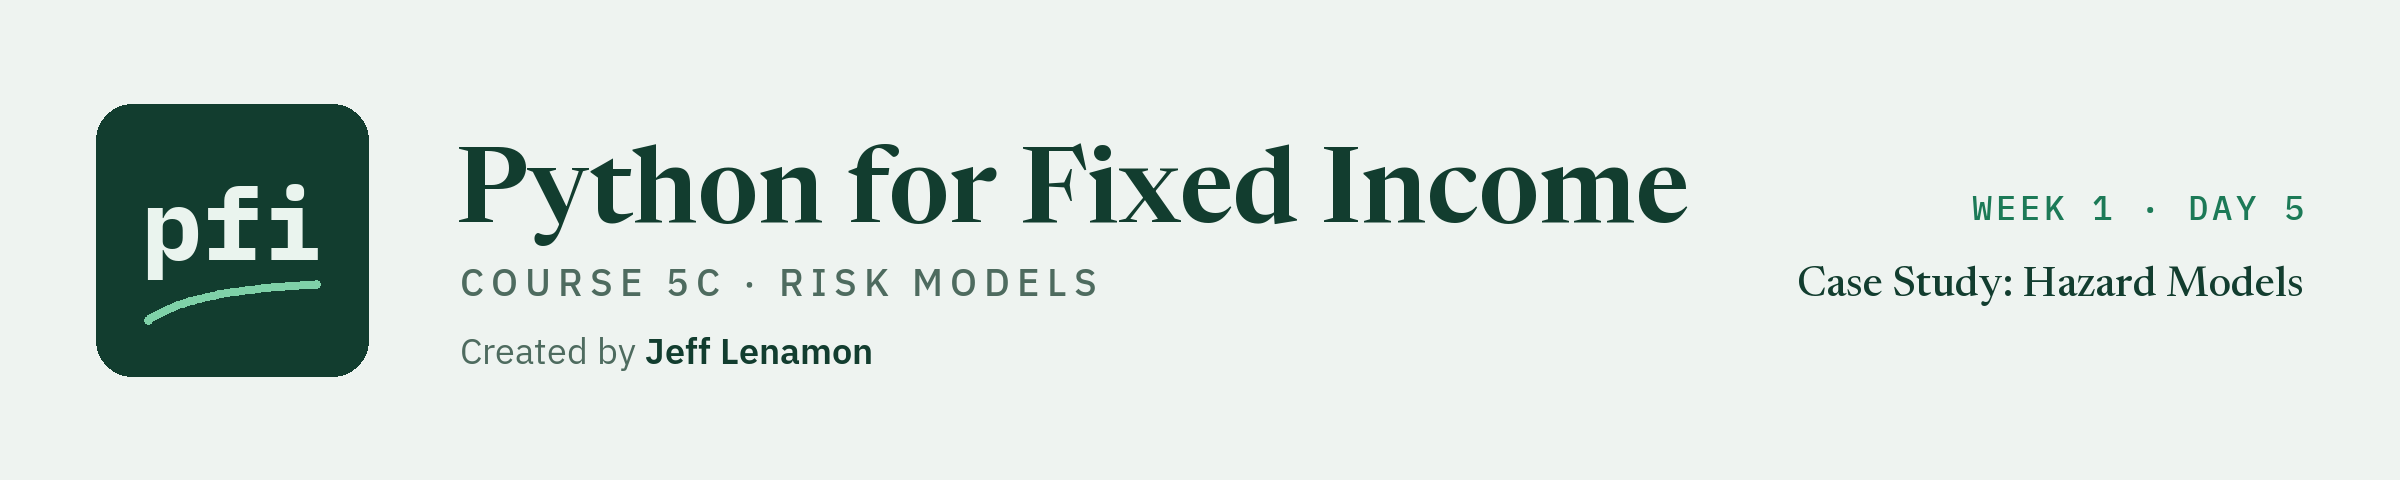

# Case Study: Hazard Models

Week 1, Day 5. Hazard models that use each firm's own rating, leverage, and coverage, year by year, then a case study: does a model fitted on earlier years rank and size the defaults of later ones?

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course5c_risk_models/week1/day5/05_case_study_hazard_models.ipynb)

Day 4 drew survival curves for groups of firms. A curve for "the B firms" treats every B firm alike, and lets a firm's rating at entry stand for its whole history. Today's models put each firm's own numbers, year by year, into the hazard: its rating, its leverage, its interest coverage. Two models do that. The **Cox model** says how much each covariate multiplies the hazard, without saying what the hazard is. The **discrete-time hazard** is a logistic regression on firm-years, which gives each firm-year its own default chance. The case study then asks whether a model fitted on earlier study years would have ranked and sized the defaults of later ones.

* **The firms are synthetic, and their model is known.** The cohort's generator, written in the repo's `DATA.md`, gives the default chance of every firm-year a formula with planted coefficients. Today's models are checked against those.
* **Only the development years, 1 to 14.** The held-out years 15 to 20 stay closed until the capstone.
* **Names.** A model's output is "a hazard ratio", "a fitted hazard", or "the model's default probability for that firm-year". It is never a forecast of defaults, a credit decision, or a statement about any real firm.

Today you will:

1. Build the firm-year table and check its history (`person_period`).
2. Fit a Cox model with covariates that move year by year, read hazard ratios, and sweep its settings.
3. Check the proportional-hazards assumption on early and late years.
4. Fit a discrete-time hazard, set its coefficients beside the planted ones, and turn yearly hazards into a firm's survival curve (`hazard_to_survival`).
5. Case study: score a walk-forward hazard model by AUC and by calibration, and say what it shows and where it fails.

Q. Set up today's work folder: the thread settings, the seed, the cohort, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course5c_risk_models/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scipy, statsmodels, or scikit-learn is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course5c_risk_models/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5c_05_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["course5c_cohort.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5c_05__wakm9_o, in your temp folder
Data files from the data folder of the course repo: course5c_cohort.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, unchanged. `riskkit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `riskkit.py` and `test_riskkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile riskkit.py
"""riskkit: risk models for a bond desk, built day by day in Course 5C.

Conventions, stated once:
- Money is in US$. Rate and spread moves are in bp. A default probability is a fraction a year: 0.02 is 2 percent.
- A loss is a positive number of US$. P&L is positive for a gain.
- Every random draw comes from a numpy Generator the caller passes in as rng. Nothing here seeds a generator or
  uses the legacy np.random functions, so one seed at the top of a notebook decides every draw.
- The inputs are the course's synthetic book, its synthetic cohort, or past data. Nothing here describes a real
  security or a real issuer.
"""
import math

import numpy as np
from scipy.stats import norm

import mlkit  # noqa: F401  (the past-only checks, used from day 5)


def mc_mean(draws) -> tuple[float, float]:
    """The Monte Carlo estimate of a mean, and its standard error.

    Input: draws, a 1-D array of independent trial outcomes: at least 2, none of them NaN.
    Output: (mean, standard error). The standard error is the sample standard deviation (ddof=1) over the
    square root of the number of draws: how far the mean of this many draws typically lands from the true mean.
    Raises ValueError for fewer than 2 draws, more than one dimension, or a NaN.
    """
    values = np.asarray(draws, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("draws must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("draws hold a NaN")
    return float(values.mean()), float(values.std(ddof=1) / math.sqrt(len(values)))


def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
    """How many independent trials put a Monte Carlo mean within half_width of the true mean, at this confidence.

    n = ceil((z * sd / half_width) ** 2), with z the two-sided normal quantile (1.96 at 0.95).
    Inputs: sd, the standard deviation of one trial, and half_width, in the same unit, both above 0; confidence
    strictly between 0 and 1.
    Output: the number of trials, a whole number.
    Raises ValueError for an sd or half_width that is not above 0, or a confidence outside (0, 1).
    """
    if sd <= 0 or half_width <= 0:
        raise ValueError("sd and half_width must be above 0")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1")
    z = norm.ppf(0.5 + confidence / 2)
    return math.ceil((z * sd / half_width) ** 2)


def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
    """n standard normal draws in antithetic pairs: n // 2 draws z, then their mirror images -z.

    Inputs: rng, a numpy Generator; n, a positive even number.
    Output: an array of n draws. Draw i and draw i + n // 2 are a pair (z and -z), so the draws' mean is 0 exactly.
    A pair is not two independent draws: average each pair before computing a standard error.
    Raises ValueError for an n that is odd or not above 0.
    """
    if n <= 0 or n % 2:
        raise ValueError("n must be a positive even number")
    half = rng.standard_normal(n // 2)
    return np.concatenate([half, -half])


import pandas as pd  # dated tables: the book's P&L by day
from scipy.stats import chi2  # the chi-squared distribution of Kupiec's test


def historical_pnl(book, rate_moves, spread_moves):
    """The book's P&L on each past day, had that day's rate and spread moves happened to today's book.

    For each bond and day: the rate move is the Treasury change at the bond's years to maturity, read off the curve
    by straight-line interpolation between the two nearest tenors (the first or last tenor beyond the ends); the
    spread move is the bond's OAS times the relative change in its spread index (the DTS approach). The P&L is
    minus market value x (duration x rate move + spread duration x spread move) / 10,000. First order only: no
    convexity, no carry, no roll down the curve.
    Inputs:
    - book: a DataFrame with one row per bond and the columns market_value (US$), duration, spread_duration, oas
      (bp), years_to_maturity, and spread_index (the name of a column of spread_moves).
    - rate_moves: a DataFrame of daily Treasury changes in bp, one row per date, one column per tenor in years.
    - spread_moves: a DataFrame of daily relative changes of each spread index (0.01 is 1 percent wider), on the
      same dates as rate_moves.
    Output: a DataFrame on those dates with the columns rates, spreads, and total, in US$.
    Raises ValueError for a missing book column, an unknown spread index, dates that differ, or a NaN in the moves.
    """
    needed = ["market_value", "duration", "spread_duration", "oas", "years_to_maturity", "spread_index"]
    missing = [name for name in needed if name not in book.columns]
    if missing:
        raise ValueError(f"book lacks the columns {missing}")
    unknown = sorted(set(book["spread_index"]) - set(spread_moves.columns))
    if unknown:
        raise ValueError(f"spread_moves has no column for the spread indexes {unknown}")
    if not rate_moves.index.equals(spread_moves.index):
        raise ValueError("rate_moves and spread_moves must be on the same dates")
    if rate_moves.isna().any().any() or spread_moves[list(set(book["spread_index"]))].isna().any().any():
        raise ValueError("the moves hold a NaN")
    tenors = np.asarray(rate_moves.columns, dtype=float)
    # interpolation is linear in the curve's values, so each bond's weight on each tenor is the curve 0 everywhere
    # but 1 at that tenor, read at the bond's maturity
    weights = np.column_stack([np.interp(book["years_to_maturity"], tenors, np.eye(len(tenors))[j])
                               for j in range(len(tenors))])
    bond_rate_moves = rate_moves.to_numpy() @ weights.T
    bond_spread_moves = spread_moves[book["spread_index"]].to_numpy() * book["oas"].to_numpy()
    rates = -(bond_rate_moves * (book["duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    spreads = -(bond_spread_moves * (book["spread_duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    return pd.DataFrame({"rates": rates, "spreads": spreads, "total": rates + spreads}, index=rate_moves.index)


def var_es(pnl, level: float = 0.99) -> tuple[float, float]:
    """The VaR and the expected shortfall of a sample of P&L, both as positive US$ losses.

    VaR at level (for example 0.99) is minus the (1 - level) quantile of the P&L, with linear interpolation between
    the two nearest values: Excel's PERCENTILE.INC. Expected shortfall is minus the mean P&L on the days at or below
    that quantile: the average loss on the days the loss is at least the VaR, so it is never below the VaR.
    Inputs: pnl, a 1-D array of at least 2 values in US$, a gain positive, none of them NaN; level strictly between
    0.5 and 1.
    Output: (VaR, expected shortfall), in US$.
    Raises ValueError for fewer than 2 values, more than one dimension, a NaN, or a level outside (0.5, 1).
    """
    values = np.asarray(pnl, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("pnl must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("pnl holds a NaN")
    if not 0.5 < level < 1:
        raise ValueError("level must be between 0.5 and 1")
    cutoff = float(np.quantile(values, 1 - level))
    return -cutoff, -float(values[values <= cutoff].mean())


def kupiec_pof(exceptions: int, n: int, level: float) -> tuple[float, float]:
    """Kupiec's proportion-of-failures test: is the count of VaR exceptions in line with the VaR's level?

    Under a correct VaR each of n days is an exception with chance p = 1 - level, independently. The statistic is
    the likelihood ratio LR = -2 ln[(1 - p)^(n - x) p^x] + 2 ln[(1 - x/n)^(n - x) (x/n)^x] for x exceptions, which
    is close to a chi-squared with 1 degree of freedom when the VaR is right.
    Inputs: exceptions, a whole number from 0 to n; n, the number of days tested, above 0; level strictly between
    0 and 1.
    Output: (LR, p-value). A small p-value says the count is hard to square with the level: too many exceptions,
    or too few.
    Raises ValueError for a count outside 0 to n, an n that is not above 0, or a level outside (0, 1).
    """
    if n <= 0 or not 0 <= exceptions <= n:
        raise ValueError("exceptions must be between 0 and n, and n above 0")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    p, x = 1 - level, exceptions
    observed = x / n

    def log_likelihood(q: float) -> float:
        # x ln q + (n - x) ln(1 - q), with 0 ln 0 taken as 0
        return (x * math.log(q) if x else 0.0) + ((n - x) * math.log(1 - q) if n - x else 0.0)

    lr = max(0.0, -2 * (log_likelihood(p) - log_likelihood(observed)))
    return lr, float(chi2.sf(lr, 1))


def one_factor_defaults(pd, rho: float, n_sims: int, rng: np.random.Generator) -> np.ndarray:
    """Simulated defaults of a group of bonds whose defaults move together through one common factor.

    In each scenario every bond's asset value is sqrt(rho) x Z + sqrt(1 - rho) x e, with Z one standard normal draw
    shared by every bond (the state of the economy) and e a standard normal draw of the bond's own. A bond defaults
    when its asset value is below the normal quantile of its default probability, so each bond still defaults with
    exactly its own probability, and rho sets how often they default together.
    Inputs: pd, a number or a 1-D array of annual default probabilities, one per bond, each strictly between 0 and
    1; rho, the asset correlation, from 0 up to (not including) 1; n_sims, the number of scenarios, above 0; rng, a
    numpy Generator.
    Output: a boolean array of shape (n_sims, number of bonds): True where that bond defaulted in that scenario.
    Raises ValueError for a pd outside (0, 1), a rho outside [0, 1), or an n_sims that is not above 0.
    """
    probabilities = np.atleast_1d(np.asarray(pd, dtype=float))
    if probabilities.ndim != 1 or not ((probabilities > 0) & (probabilities < 1)).all():
        raise ValueError("pd must be a number or a 1-D array, each strictly between 0 and 1")
    if not 0 <= rho < 1:
        raise ValueError("rho must be from 0 up to 1")
    if n_sims <= 0:
        raise ValueError("n_sims must be above 0")
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(probabilities)))
    assets = math.sqrt(rho) * common + math.sqrt(1 - rho) * own
    return assets < norm.ppf(probabilities)


def vasicek_quantile(pd: float, rho: float, q: float) -> float:
    """The default rate of a very large group of alike bonds that is not exceeded with probability q (Vasicek).

    N((N^-1(pd) + sqrt(rho) x N^-1(q)) / sqrt(1 - rho)), N the standard normal distribution: the one-factor model's
    default rate when the common factor sits at its own q quantile on the bad side. Exact only in the limit of
    many bonds, each with the same pd and rho.
    Inputs: pd, rho, and q, each strictly between 0 and 1.
    Output: a default rate between 0 and 1.
    Raises ValueError for any input outside (0, 1).
    """
    for name, value in (("pd", pd), ("rho", rho), ("q", q)):
        if not 0 < value < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1")
    return float(norm.cdf((norm.ppf(pd) + math.sqrt(rho) * norm.ppf(q)) / math.sqrt(1 - rho)))


def loss_distribution(book, defaults, lgd) -> np.ndarray:
    """The credit loss of the book in each simulated scenario, in US$.

    A defaulted bond loses its market value (its exposure at default) times its loss given default; a bond that did
    not default loses nothing.
    Inputs: book, a DataFrame with a market_value column (US$), one row per bond; defaults, a boolean array of shape
    (scenarios, bonds), as one_factor_defaults returns; lgd, the loss given default as a share between 0 and 1: a
    number, one per bond, or one per scenario and bond.
    Output: an array of one loss per scenario, in US$ (positive is a loss).
    Raises ValueError for defaults whose number of columns is not the number of bonds, or an lgd outside [0, 1].
    """
    hits = np.asarray(defaults, dtype=bool)
    exposure = book["market_value"].to_numpy(dtype=float)
    if hits.ndim != 2 or hits.shape[1] != len(exposure):
        raise ValueError("defaults must have one column per bond of the book")
    shares = np.asarray(lgd, dtype=float)
    if ((shares < 0) | (shares > 1)).any():
        raise ValueError("lgd must be between 0 and 1")
    return (hits * shares * exposure).sum(axis=1)


def kaplan_meier(time, event):
    """The Kaplan-Meier survival curve of a group observed for different lengths of time.

    Each subject is followed for time periods and either has the event at the end (event 1: here, a default) or is
    censored (event 0): it left the study, or the study ended, with no event seen. At each distinct time t, the
    subjects at risk are those followed for at least t; the curve multiplies, from the first time to t, the share
    of those at risk that did not have the event: S(t) = product of (1 - events / at risk). A censored subject counts
    as at risk up to and including its last time, and is never counted as an event.
    Inputs: time, a 1-D array of observed lengths (years, for example), each above 0; event, a 1-D array of the same
    length holding 1 for an event and 0 for censored.
    Output: a DataFrame with one row per distinct time, in order, and the columns at_risk, events, censored, and
    survival (the share expected to be event-free past that time).
    Raises ValueError for arrays of different lengths, a time that is not above 0, a NaN, or an event other than 0
    or 1.
    """
    times = np.asarray(time, dtype=float)
    events = np.asarray(event, dtype=float)
    if times.ndim != 1 or times.shape != events.shape or len(times) == 0:
        raise ValueError("time and event must be 1-D arrays of the same length, not empty")
    if np.isnan(times).any() or np.isnan(events).any():
        raise ValueError("time or event holds a NaN")
    if (times <= 0).any():
        raise ValueError("every time must be above 0")
    if not np.isin(events, (0, 1)).all():
        raise ValueError("event must hold only 0 and 1")
    distinct = np.unique(times)
    at_risk = np.array([(times >= t).sum() for t in distinct])
    had_event = np.array([((times == t) & (events == 1)).sum() for t in distinct])
    censored = np.array([((times == t) & (events == 0)).sum() for t in distinct])
    survival = np.cumprod(1 - had_event / at_risk)
    return pd.DataFrame({"at_risk": at_risk, "events": had_event, "censored": censored, "survival": survival},
                        index=pd.Index(distinct, name="time"))

Writing riskkit.py


In [5]:
%%writefile test_riskkit.py
"""Tests for riskkit.py. Small seeded arrays only; no data file is read."""
import math

import numpy as np
import pytest

import riskkit


def test_mc_mean_hand():
    # mean 2.5; sample standard deviation sqrt(5/3); standard error that over sqrt(4)
    mean, se = riskkit.mc_mean([1.0, 2.0, 3.0, 4.0])
    assert mean == 2.5
    assert se == pytest.approx(math.sqrt(5 / 3) / 2, rel=1e-12)


def test_mc_mean_refuses():
    with pytest.raises(ValueError, match="at least 2"):
        riskkit.mc_mean([1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.mc_mean([1.0, float("nan"), 3.0])


def test_mc_mean_covers_a_known_mean():
    # 2 percent default, US$600,000 lost: the true mean is US$12,000; 40,000 draws land within 4 standard errors
    rng = np.random.default_rng(42)
    losses = np.where(rng.random(40_000) < 0.02, 600_000.0, 0.0)
    mean, se = riskkit.mc_mean(losses)
    assert abs(mean - 12_000.0) < 4 * se


def test_trials_needed_hand():
    # z at 95 percent is 1.959964; (1.959964 * 10 / 1) ** 2 = 384.15, so 385 trials
    assert riskkit.trials_needed(10.0, 1.0) == 385
    # halving the half-width takes four times the trials, give or take the rounding up
    assert riskkit.trials_needed(10.0, 0.5) == 1_537
    with pytest.raises(ValueError, match="above 0"):
        riskkit.trials_needed(10.0, 0.0)
    with pytest.raises(ValueError, match="between 0 and 1"):
        riskkit.trials_needed(10.0, 1.0, confidence=1.0)


def test_antithetic_normals_pairs():
    draws = riskkit.antithetic_normals(np.random.default_rng(42), 10)
    assert len(draws) == 10
    assert np.array_equal(draws[5:], -draws[:5])
    assert draws.mean() == 0.0
    with pytest.raises(ValueError, match="even"):
        riskkit.antithetic_normals(np.random.default_rng(42), 7)


def test_antithetic_normals_same_seed_same_draws():
    first = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    second = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    assert np.array_equal(first, second)


import pandas as pd


def _one_bond(years):
    return pd.DataFrame({"market_value": [1_000_000.0], "duration": [5.0], "spread_duration": [5.0], "oas": [100.0],
                         "years_to_maturity": [years], "spread_index": ["ig"]})


def test_historical_pnl_hand():
    # 4 years sits halfway between the 3 and 5 year tenors: a 15 bp move, and 10 percent of 100 bp is 10 bp
    dates = pd.to_datetime(["2020-01-02"])
    rates = pd.DataFrame({3.0: [10.0], 5.0: [20.0]}, index=dates)
    spreads = pd.DataFrame({"ig": [0.10]}, index=dates)
    pnl = riskkit.historical_pnl(_one_bond(4.0), rates, spreads)
    assert pnl.loc[dates[0], "rates"] == pytest.approx(-7_500.0, rel=1e-12)
    assert pnl.loc[dates[0], "spreads"] == pytest.approx(-5_000.0, rel=1e-12)
    assert pnl.loc[dates[0], "total"] == pytest.approx(-12_500.0, rel=1e-12)
    # beyond the last tenor the last tenor's move is used
    assert riskkit.historical_pnl(_one_bond(8.0), rates, spreads).loc[dates[0], "rates"] == pytest.approx(-10_000.0)


def test_historical_pnl_refuses():
    dates = pd.to_datetime(["2020-01-02", "2020-01-03"])
    rates = pd.DataFrame({3.0: [10.0, 1.0], 5.0: [20.0, 2.0]}, index=dates)
    with pytest.raises(ValueError, match="same dates"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"ig": [0.1]}, index=dates[:1]))
    with pytest.raises(ValueError, match="no column"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"hy": [0.1, 0.2]}, index=dates))
    with pytest.raises(ValueError, match="NaN"):
        riskkit.historical_pnl(_one_bond(4.0), rates.where(rates > 1), pd.DataFrame({"ig": [0.1, 0.2]}, index=dates))


def test_var_es_hand():
    # losses of 1 to 100: the 5 percent quantile of the P&L sits 4.95 of the way from -100 to -99, so VaR 95.05;
    # the days at or below it lose 100, 99, 98, 97, and 96, an average of 98
    var, es = riskkit.var_es(-np.arange(1.0, 101.0), 0.95)
    assert var == pytest.approx(95.05, rel=1e-12)
    assert es == pytest.approx(98.0, rel=1e-12)


def test_var_es_shortfall_at_least_var():
    pnl = np.random.default_rng(42).standard_t(4, 5_000)
    for level in (0.95, 0.99):
        var, es = riskkit.var_es(pnl, level)
        assert es >= var > 0


def test_var_es_refuses():
    with pytest.raises(ValueError, match="NaN"):
        riskkit.var_es([1.0, float("nan"), -2.0])
    with pytest.raises(ValueError, match="between 0.5 and 1"):
        riskkit.var_es([1.0, -2.0, 3.0], 0.01)


def test_kupiec_pof_hand():
    # exactly the expected count: the statistic is 0 and the p-value 1
    assert riskkit.kupiec_pof(10, 1_000, 0.99) == pytest.approx((0.0, 1.0))
    # 5 exceptions in 250 days at 99 percent, against the formula written out
    x, n, p = 5, 250, 0.01
    lr = -2 * ((n - x) * math.log(1 - p) + x * math.log(p) - (n - x) * math.log(1 - x / n) - x * math.log(x / n))
    assert riskkit.kupiec_pof(x, n, 0.99)[0] == pytest.approx(lr, rel=1e-12)
    # no exception at all is too few for a long sample
    assert riskkit.kupiec_pof(0, 2_000, 0.99)[1] < 0.01


def test_kupiec_pof_refuses():
    with pytest.raises(ValueError, match="between 0 and n"):
        riskkit.kupiec_pof(11, 10, 0.99)


from scipy.stats import norm


def test_one_factor_defaults_shape_and_rate():
    defaults = riskkit.one_factor_defaults([0.02, 0.10], 0.3, 50_000, np.random.default_rng(42))
    assert defaults.shape == (50_000, 2) and defaults.dtype == bool
    # each bond still defaults with its own probability, whatever rho is
    assert defaults[:, 0].mean() == pytest.approx(0.02, abs=0.003)
    assert defaults[:, 1].mean() == pytest.approx(0.10, abs=0.006)


def test_one_factor_defaults_correlation_fattens_the_count():
    # 100 alike bonds: the mean count stays at 2, the chance of 10 or more grows with rho
    rng_a, rng_b = np.random.default_rng(42).spawn(2)
    independent = riskkit.one_factor_defaults(np.full(100, 0.02), 0.0, 20_000, rng_a).sum(axis=1)
    correlated = riskkit.one_factor_defaults(np.full(100, 0.02), 0.3, 20_000, rng_b).sum(axis=1)
    assert abs(independent.mean() - correlated.mean()) < 0.2
    assert (correlated >= 10).mean() > 10 * max((independent >= 10).mean(), 1e-4)


def test_one_factor_defaults_refuses():
    with pytest.raises(ValueError, match="strictly between 0 and 1"):
        riskkit.one_factor_defaults([0.02, 0.0], 0.2, 10, np.random.default_rng(42))
    with pytest.raises(ValueError, match="rho"):
        riskkit.one_factor_defaults(0.02, 1.0, 10, np.random.default_rng(42))


def test_vasicek_quantile_hand():
    # at q = 0.5 the common factor sits at 0: N(N^-1(pd) / sqrt(1 - rho))
    assert riskkit.vasicek_quantile(0.02, 0.2, 0.5) == pytest.approx(norm.cdf(norm.ppf(0.02) / math.sqrt(0.8)), rel=1e-12)
    # a rho near 0 gives back pd at any q
    assert riskkit.vasicek_quantile(0.02, 1e-12, 0.999) == pytest.approx(0.02, rel=1e-4)
    with pytest.raises(ValueError, match="rho"):
        riskkit.vasicek_quantile(0.02, 0.0, 0.999)


def test_loss_distribution_hand():
    book = pd.DataFrame({"market_value": [100.0, 200.0, 300.0]})
    defaults = np.array([[True, False, True], [False, False, False]])
    # scenario 1 loses 60 percent of 100 and of 300; scenario 2 loses nothing
    assert riskkit.loss_distribution(book, defaults, 0.6).tolist() == pytest.approx([240.0, 0.0])
    assert riskkit.loss_distribution(book, defaults, [0.5, 0.6, 0.7]).tolist() == pytest.approx([260.0, 0.0])
    with pytest.raises(ValueError, match="one column per bond"):
        riskkit.loss_distribution(book, defaults[:, :2], 0.6)


def test_kaplan_meier_hand():
    # six subjects: events at 1 and 3, censored at 2, 3, 4, and 4
    table = riskkit.kaplan_meier([1, 2, 3, 3, 4, 4], [1, 0, 1, 0, 0, 0])
    assert table.index.tolist() == [1.0, 2.0, 3.0, 4.0]
    assert table["at_risk"].tolist() == [6, 5, 4, 2]
    assert table["events"].tolist() == [1, 0, 1, 0]
    assert table["censored"].tolist() == [0, 1, 1, 2]
    # 5/6 after time 1, unchanged at 2 (a censoring is not an event), then times 3/4 at time 3
    assert table["survival"].tolist() == pytest.approx([5 / 6, 5 / 6, 5 / 6 * 3 / 4, 5 / 6 * 3 / 4])


def test_kaplan_meier_without_censoring_is_the_plain_share():
    # with no censoring, survival past t is simply the share still event-free
    time = np.array([1, 2, 2, 3, 5])
    table = riskkit.kaplan_meier(time, np.ones(5))
    assert table["survival"].tolist() == pytest.approx([0.8, 0.4, 0.2, 0.0])


def test_kaplan_meier_refuses():
    with pytest.raises(ValueError, match="same length"):
        riskkit.kaplan_meier([1, 2], [1])
    with pytest.raises(ValueError, match="above 0"):
        riskkit.kaplan_meier([0, 2], [1, 0])
    with pytest.raises(ValueError, match="only 0 and 1"):
        riskkit.kaplan_meier([1, 2], [1, 2])

Writing test_riskkit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import riskkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(riskkit)

# the functions defined in riskkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(riskkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "riskkit" and not name.startswith("_")]
print(f"riskkit functions: {functions}")

riskkit functions: ['mc_mean', 'trials_needed', 'antithetic_normals', 'historical_pnl', 'var_es', 'kupiec_pof', 'one_factor_defaults', 'vasicek_quantile', 'loss_distribution', 'kaplan_meier']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is the course's own. It writes `riskkit.py` and `test_riskkit.py` as day 4 left them.

## 5.1 The Firm-Year Table

**How it works.** A hazard model with covariates that change needs one row per firm per year at risk: a **person-period** table. Each row holds the covariates as they stood at the start of the year, and an event flag that is 1 only in the year of default. The table must be a clean history: no year twice, no gap, and nothing after a default or an exit, or the model will count a firm at risk when it was not. The settings are the years kept and the covariates added. What comes out is the table every model today is fitted on.

Q. Add `person_period` to `riskkit.py`. Read the docstring first.

In [9]:
%%writefile -a riskkit.py


def person_period(cohort):
    """The firm-years at risk, checked and ready for a discrete-time hazard model: one row per firm and study year.

    A firm-year row covers one firm in one study year, with its covariates dated at the start of that year. This
    checks the rows make a clean history (no repeated year, no gap between a firm's years, nothing after a default
    or an exit) and adds three columns: event (1 in the year of default), log_coverage (the natural log of coverage,
    because the hazard moves with coverage's ratio, not its difference), and early_years (1 in years 2 to 4 since
    entry, the cohort's planted bump in the hazard).
    Input: cohort, a DataFrame with firm_id, study_year, years_since_entry, coverage, default, and exit.
    Output: a copy sorted by firm_id and study_year with the three columns added.
    Raises ValueError for a missing column, a coverage that is not above 0, a firm with a repeated or missing study
    year, or a firm with a row after its default or its exit.
    """
    needed = ["firm_id", "study_year", "years_since_entry", "coverage", "default", "exit"]
    missing = [name for name in needed if name not in cohort.columns]
    if missing:
        raise ValueError(f"cohort lacks the columns {missing}")
    if (cohort["coverage"] <= 0).any():
        raise ValueError("coverage must be above 0 to take its log")
    rows = cohort.sort_values(["firm_id", "study_year"]).reset_index(drop=True)
    by_firm = rows.groupby("firm_id")
    if (by_firm["study_year"].diff().dropna() != 1).any():
        raise ValueError("a firm has a repeated or missing study year")
    # a default or an exit must be the firm's last row: nothing after it
    ended = by_firm["default"].cumsum() + by_firm["exit"].cumsum()
    if ((ended - rows["default"] - rows["exit"]) > 0).any():
        raise ValueError("a firm has a row after its default or its exit")
    rows["event"] = rows["default"].astype(int)
    rows["log_coverage"] = np.log(rows["coverage"])
    rows["early_years"] = rows["years_since_entry"].between(2, 4).astype(int)
    return rows

Appending to riskkit.py


* Most of the function is checks. The cohort file already has one row per firm-year; the function's job is to refuse a broken one and add the three columns every model today uses.
* `log_coverage` is the log of coverage: going from 1 times to 2 times interest coverage matters about as much as going from 4 to 8.

In [10]:
%%writefile -a test_riskkit.py


def _firm_years():
    # two firms: F1 watched three years and defaults in its third; F2 watched two years, still at risk
    return pd.DataFrame({"firm_id": ["F2", "F1", "F1", "F2", "F1"], "study_year": [5, 3, 1, 6, 2],
                         "years_since_entry": [1, 3, 1, 2, 2], "coverage": [4.0, 1.0, 3.0, 5.0, 2.0],
                         "default": [0, 1, 0, 0, 0], "exit": [0, 0, 0, 0, 0]})


def test_person_period_hand():
    rows = riskkit.person_period(_firm_years())
    assert rows["firm_id"].tolist() == ["F1", "F1", "F1", "F2", "F2"]
    assert rows["study_year"].tolist() == [1, 2, 3, 5, 6]
    assert rows["event"].tolist() == [0, 0, 1, 0, 0]
    assert rows["early_years"].tolist() == [0, 1, 1, 0, 1]
    assert rows["log_coverage"].tolist() == pytest.approx(np.log([3.0, 2.0, 1.0, 4.0, 5.0]).tolist())


def test_person_period_refuses_a_broken_history():
    gap = _firm_years()
    gap.loc[2, "study_year"] = 0  # F1's first year becomes year 0: a gap before year 2
    with pytest.raises(ValueError, match="missing study year"):
        riskkit.person_period(gap)
    after = _firm_years()
    after.loc[4, "default"] = 1  # F1 now defaults in year 2 and still has a row in year 3
    with pytest.raises(ValueError, match="after its default"):
        riskkit.person_period(after)

Appending to test_riskkit.py


In [11]:
importlib.reload(riskkit)
print(f"person_period in riskkit: {hasattr(riskkit, 'person_period')}")

person_period in riskkit: True


In [12]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................                                                  [100%]
23 passed in 1.80s



* `23 passed`. The refusal test plants two broken histories: a gap in a firm's years, and a row after a default.

Q. Build the firm-year table of the development years, and look at one firm that defaulted.

In [13]:
# the synthetic cohort's development years: invented firms, study years 1 to 14
cohort = pd.read_csv("course5c_cohort.csv")
DEVELOPMENT_END = 14
firm_years = riskkit.person_period(cohort[cohort["study_year"] <= DEVELOPMENT_END])
print(f"{len(firm_years):,} firm-years of {firm_years['firm_id'].nunique():,} firms; {int(firm_years['event'].sum())} defaults")
print(firm_years[firm_years["firm_id"] == firm_years.loc[firm_years["event"] == 1, "firm_id"].iloc[0]].to_string(index=False))

18,503 firm-years of 3,504 firms; 345 defaults
firm_id  study_year  years_since_entry   sector rating  rating_score  leverage  coverage  default  exit  event  log_coverage  early_years
  F0002           1                  1 Consumer      B            15      4.92      7.18        0     0      0      1.971299            0
  F0002           2                  2 Consumer      B            15      5.09      9.72        1     0      1      2.274186            1


* 18,503 firm-years and 345 defaults, as on days 3 and 4. Firm F0002's rows show its rating, leverage, and coverage moving year by year, and the event flag set only in its last row.

## 5.2 The Cox Model

**How it works.** The **Cox proportional hazards model** writes a firm's hazard as a baseline hazard, the same for every firm at a given time since entry, times exp(b1 x1 + b2 x2 + ...). The baseline is left free, any shape at all; only the b's are estimated, from which firm defaulted at each time among those at risk. exp(b) is a **hazard ratio**: the factor by which a one-unit rise in that covariate multiplies the hazard, at every time. With one row per firm-year and each row's entry time set to the start of its year, the covariates can change year by year. The settings are the covariates, how tied event times are handled, and any strata. What comes out is a hazard ratio for each covariate, with its interval.

Q. Fit a Cox model on rating score, leverage, and log coverage, with each firm-year as its own interval.

In [14]:
from statsmodels.duration.hazard_regression import PHReg

# each firm-year is an interval of time since entry, from its start (entry) to its end (time): the covariates of
# that year apply on that interval, so a firm's rating, leverage, and coverage move year by year
COVARIATES = ["rating_score", "leverage", "log_coverage"]
cox = PHReg(firm_years["years_since_entry"], firm_years[COVARIATES], status=firm_years["event"],
            entry=firm_years["years_since_entry"] - 1, ties="efron").fit()
interval = np.exp(cox.conf_int())
hazard_ratios = pd.DataFrame({"coefficient": cox.params, "standard error": cox.bse, "hazard ratio": np.exp(cox.params),
                              "95% low": interval[:, 0], "95% high": interval[:, 1]}, index=COVARIATES)
hazard_ratios.index.name = "covariate"
print(hazard_ratios.round(4).to_string())

              coefficient  standard error  hazard ratio  95% low  95% high
covariate                                                                 
rating_score       0.3979          0.0273        1.4887   1.4111    1.5706
leverage           0.1592          0.0619        1.1725   1.0387    1.3237
log_coverage      -0.6334          0.1071        0.5308   0.4303    0.6547


In [15]:
plotkit.styled(hazard_ratios, ["hazard ratio"], "Cox model on the synthetic cohort's development firm-years: coefficients "
               "and hazard ratios with 95 percent intervals", fmt="{:,.4f}")

,coefficient,standard error,hazard ratio,95% low,95% high
covariate,,,,,
rating_score,0.3979,0.0273,1.4887,1.4111,1.5706
leverage,0.1592,0.0619,1.1725,1.0387,1.3237
log_coverage,-0.6334,0.1071,0.5308,0.4303,0.6547


* Each notch down the rating scale multiplies the hazard by 1.489, with an interval that excludes 1 by a wide margin. A turn of extra leverage (one more times EBITDA in debt) multiplies it by 1.173.
* Log coverage has a hazard ratio of 0.531 per unit of its log: halving a firm's interest coverage multiplies its hazard by 1.55, other things equal.
* The model describes the invented firms of the cohort; it is never a credit decision about any of them.

Q. Read every setting of `PHReg` from the installed library.

In [16]:
import inspect

# every setting of PHReg, read from the installed library, with what each one does
meaning = {
    "endog": ("the time at the end of each row's interval", "years_since_entry"),
    "exog": ("the covariates, one column each", "rating score, leverage, log coverage"),
    "status": ("1 if the interval ends in the event, 0 if censored", "event"),
    "entry": ("the time each row's interval starts (left truncation)", "years_since_entry - 1: one row per year"),
    "strata": ("groups that each get their own baseline hazard", "swept below: sector"),
    "offset": ("a fixed part of the linear term, not estimated", "not used"),
    "ties": ("how events at the same time are handled: breslow or efron", "efron; swept below"),
    "missing": ("what to do with missing values", "'drop' (the cohort has none)"),
}
parameters = [name for name in inspect.signature(PHReg.__init__).parameters if name not in ("self", "kwargs")]
print(f"every setting described: {sorted(parameters) == sorted(meaning)}")
phreg_settings = pd.DataFrame({
    "default": [inspect.signature(PHReg.__init__).parameters[name].default for name in parameters],
    "what it controls": [meaning[name][0] for name in parameters],
    "today": [meaning[name][1] for name in parameters],
}, index=pd.Index(parameters, name="setting"))
phreg_settings["default"] = phreg_settings["default"].map(lambda value: "required" if value is inspect.Parameter.empty else repr(value))

plotkit.styled(phreg_settings, [], "Every setting of statsmodels' PHReg, read from the installed library")

every setting described: True


,default,what it controls,today
setting,,,
endog,required,the time at the end of each row's interval,years_since_entry
exog,required,"the covariates, one column each","rating score, leverage, log coverage"
status,None,"1 if the interval ends in the event, 0 if censored",event
entry,None,the time each row's interval starts (left truncation),years_since_entry - 1: one row per year
strata,None,groups that each get their own baseline hazard,swept below: sector
offset,None,"a fixed part of the linear term, not estimated",not used
ties,'breslow',how events at the same time are handled: breslow or efron,efron; swept below
missing,'drop',what to do with missing values,'drop' (the cohort has none)


* `ties` matters here more than usual: time is counted in whole years, so the 345 defaults fall on only 14 distinct times. Breslow's method treats the firms that defaulted in the same year as if they failed one after another from the same risk set; Efron's adjusts the risk set as they go. `strata` gives each group its own baseline hazard instead of a hazard ratio.

Q. Sweep the two settings that change the fit: Breslow against Efron, and sector as strata.

In [17]:
# the same model three ways: Breslow's and Efron's handling of tied years, and sectors as strata
def cox_fit(**settings):
    return PHReg(firm_years["years_since_entry"], firm_years[COVARIATES], status=firm_years["event"],
                 entry=firm_years["years_since_entry"] - 1, **settings).fit()

sweep_fits = {"ties = breslow": cox_fit(ties="breslow"), "ties = efron": cox_fit(ties="efron"),
              "ties = efron, strata = sector": cox_fit(ties="efron", strata=firm_years["sector"])}
ties_sweep = pd.DataFrame({name: fit.params for name, fit in sweep_fits.items()}, index=COVARIATES).T
ties_sweep.index.name = "settings"
print(ties_sweep.round(4).to_string())
print(f"tied years: {int(firm_years['event'].sum())} defaults fall on only {firm_years.loc[firm_years['event'] == 1, 'years_since_entry'].nunique()} distinct times")

                               rating_score  leverage  log_coverage
settings                                                           
ties = breslow                       0.3914    0.1580       -0.6135
ties = efron                         0.3979    0.1592       -0.6334
ties = efron, strata = sector        0.3999    0.1622       -0.6446
tied years: 345 defaults fall on only 14 distinct times


In [18]:
plotkit.styled(ties_sweep, [], "The Cox coefficients under two ways of handling tied years, and with sector strata", fmt="{:,.4f}")

,rating_score,leverage,log_coverage
settings,,,
ties = breslow,0.3914,0.1580,-0.6135
ties = efron,0.3979,0.1592,-0.6334
"ties = efron, strata = sector",0.3999,0.1622,-0.6446


* The coefficients move by at most 0.0199 between Breslow and Efron, well inside their standard errors: with a hazard of about 2 percent a year, few defaults share a risk set closely enough for the method to matter. Sector strata leave the coefficients nearly where they were.

Q. Add sector as covariates, one indicator per sector.

In [19]:
# sector as covariates: one indicator per sector, each measured against the first sector alphabetically
sector_columns = pd.get_dummies(firm_years["sector"], drop_first=True, dtype=float)
BASE_SECTOR = sorted(firm_years["sector"].unique())[0]
cox_sector = PHReg(firm_years["years_since_entry"], pd.concat([firm_years[COVARIATES], sector_columns], axis=1),
                   status=firm_years["event"], entry=firm_years["years_since_entry"] - 1, ties="efron").fit()
names = COVARIATES + list(sector_columns.columns)
sector_interval = np.exp(cox_sector.conf_int())
sector_ratios = pd.DataFrame({"hazard ratio": np.exp(cox_sector.params), "95% low": sector_interval[:, 0],
                              "95% high": sector_interval[:, 1], "p-value": cox_sector.pvalues}, index=names)
print(f"base sector: {BASE_SECTOR}")
print(f"sectors with a p-value below 0.05: {int((sector_ratios.loc[sector_columns.columns, 'p-value'] < 0.05).sum())} of {len(sector_columns.columns)}")
print(f"defaults per 100 firm-years by sector: {(100 * firm_years.groupby('sector')['event'].mean()).round(2).to_dict()}")

base sector: Consumer
sectors with a p-value below 0.05: 3 of 9
defaults per 100 firm-years by sector: {'Consumer': 2.46, 'Energy': 1.67, 'Financials': 1.72, 'Health Care': 1.51, 'Industrials': 2.15, 'Materials': 2.05, 'Technology': 1.33, 'Telecom': 1.87, 'Transportation': 2.38, 'Utilities': 1.52}


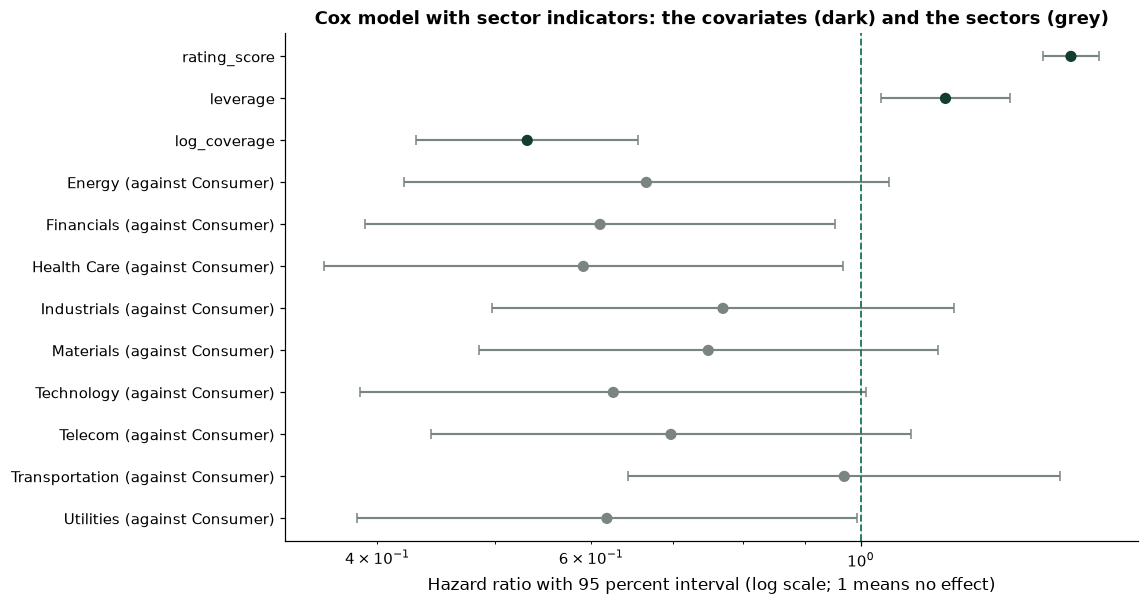

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
shown = sector_ratios.iloc[::-1]
colours = [plotkit.GREEN_DARK if name in COVARIATES else plotkit.GREY for name in shown.index]
ax.errorbar(shown["hazard ratio"], np.arange(len(shown)), xerr=[shown["hazard ratio"] - shown["95% low"], shown["95% high"] - shown["hazard ratio"]],
            fmt="none", ecolor=plotkit.GREY, elinewidth=1.4, capsize=3)
ax.scatter(shown["hazard ratio"], np.arange(len(shown)), color=colours, s=40, zorder=3)
ax.axvline(1, color=plotkit.GREEN, linestyle="--", linewidth=1.2)
ax.set_yticks(np.arange(len(shown)))
ax.set_yticklabels([name if name in COVARIATES else f"{name} (against {BASE_SECTOR})" for name in shown.index])
ax.set_xscale("log")
ax.set_xlabel("Hazard ratio with 95 percent interval (log scale; 1 means no effect)")
ax.set_title("Cox model with sector indicators: the covariates (dark) and the sectors (grey)")
ax.grid(axis="y", visible=False)
plt.show()

* How to read it: a point right of the dashed line raises the hazard, left of it lowers it; a bar that crosses the line is an interval that includes no effect. The three covariates sit far from 1. The sectors all sit left of 1, and 3 of 9 have a p-value below 0.05.
* **The generator has no sector term at all.** Every sector's ratio is measured against Consumer, the first sector alphabetically, whose firms happened to default more often in these years (2.46 defaults per 100 firm-years against 1.86 for all firms). The sector "effects" are chance in the base, and nine tests at once make a few small p-values likely. Day 3 warned that a model's output describes the data it was fitted on; this is what that looks like.

## 5.3 The Proportional-Hazards Check

**How it works.** The Cox model assumes each hazard ratio holds at every time since entry: a covariate that doubles the hazard in year 1 doubles it in year 10. One check is to fit the model on the early years and on the later ones separately and compare the coefficients. If a coefficient differs between the two by more than its standard errors allow, its effect changes with time and one hazard ratio misdescribes it. The setting is where the years are split. What comes out is two sets of coefficients and how far apart they are.

Q. Fit the model on years 1 to 4 since entry and on years 5 to 14, and compare.

In [21]:
# the proportional-hazards check: fit the same model on the early years since entry and on the later ones
ph_rows = []
for label, low, high in [("years 1 to 4", 1, 4), ("years 5 to 14", 5, 14)]:
    part = firm_years[firm_years["years_since_entry"].between(low, high)]
    fit = PHReg(part["years_since_entry"], part[COVARIATES], status=part["event"], entry=part["years_since_entry"] - 1,
                ties="efron").fit()
    for name, coefficient, error in zip(COVARIATES, fit.params, fit.bse):
        ph_rows.append({"years since entry": label, "covariate": name, "coefficient": coefficient, "standard error": error,
                        "defaults": int(part["event"].sum())})
ph_check = pd.DataFrame(ph_rows).set_index(["covariate", "years since entry"])
print(ph_check.round(4).to_string())

                                coefficient  standard error  defaults
covariate    years since entry                                       
rating_score years 1 to 4            0.3998          0.0352       241
leverage     years 1 to 4            0.1777          0.0804       241
log_coverage years 1 to 4           -0.6290          0.1282       241
rating_score years 5 to 14           0.3911          0.0446       104
leverage     years 5 to 14           0.1196          0.0996       104
log_coverage years 5 to 14          -0.6797          0.1946       104


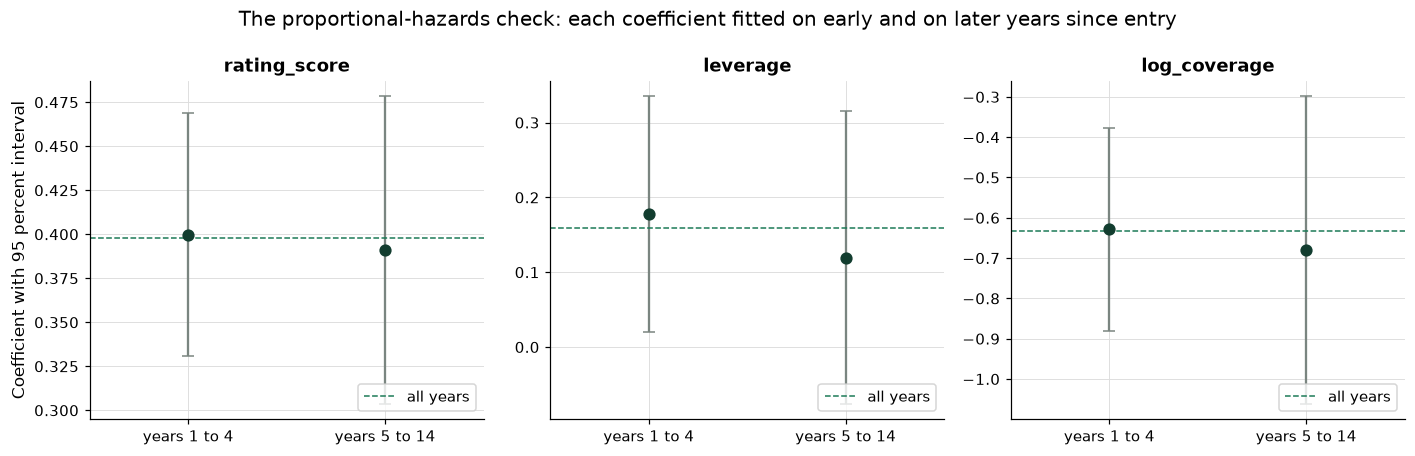

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, name in zip(axes, COVARIATES):
    part = ph_check.loc[name]
    ax.errorbar([0, 1], part["coefficient"], yerr=1.96 * part["standard error"], fmt="o", color=plotkit.GREEN_DARK,
                ecolor=plotkit.GREY, capsize=4, markersize=7)
    ax.axhline(np.asarray(cox.params)[COVARIATES.index(name)], color=plotkit.GREEN, linestyle="--", linewidth=1, label="all years")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(part.index)
    ax.set_xlim(-0.5, 1.5)
    ax.set_title(name)
    ax.legend(loc="lower right")
axes[0].set_ylabel("Coefficient with 95 percent interval")
fig.suptitle("The proportional-hazards check: each coefficient fitted on early and on later years since entry")
fig.tight_layout()
plt.show()

* How to read it: each panel is one covariate, its coefficient fitted on the early years and on the later ones, with the all-years value dashed. The pairs overlap: the largest gap is 0.45 standard errors (of the difference), below the 1.96 that would flag it. The later years have fewer defaults, so their intervals are wider.
* The cohort's generator uses the same coefficients in every year (its age bump is in the baseline, not in a coefficient), so this is the answer the check should give. On real data the same two fits are the first thing to look at.

## 5.4 The Discrete-Time Hazard

**How it works.** Time here is counted in whole years, so the hazard can be modelled as what it is: the chance that a firm at risk at the start of a year defaults during it. A **logistic regression on firm-years** does that (a published approach: Shumway, *Journal of Business*, 2001). Each firm-year is one row, its covariates dated at the start of the year, its outcome 1 in the year of default. Unlike Cox, the model gives a full default probability for each firm-year, so its hazards can be chained into a survival curve. Study-year indicators can soak up anything common to all firms in a year. The settings are the covariates and whether the year indicators are in. What comes out is a fitted hazard for every firm-year.

Q. Fit the logistic hazard, with and without study-year effects, and set its coefficients beside the generator's planted ones and the Cox model's.

In [23]:
import statsmodels.api as sm

# the discrete-time hazard: a logistic regression on firm-years, one row per firm and year at risk
FEATURES = ["rating_score", "leverage", "log_coverage", "early_years"]
logit = sm.Logit(firm_years["event"], sm.add_constant(firm_years[FEATURES])).fit(disp=0)
# the same with one indicator per study year: the common factor of each year, which the generator planted
year_columns = pd.get_dummies(firm_years["study_year"], prefix="year", drop_first=True, dtype=float)
logit_years = sm.Logit(firm_years["event"], pd.concat([sm.add_constant(firm_years[FEATURES]), year_columns], axis=1)).fit(disp=0)

PLANTED = {"rating_score": 0.38, "leverage": 0.25, "log_coverage": -0.40, "early_years": 0.30}
coefficients = pd.DataFrame({
    "planted in the generator": pd.Series(PLANTED),
    "logistic, with study-year effects": logit_years.params[FEATURES],
    "its standard error": logit_years.bse[FEATURES],
    "logistic, no study-year effects": logit.params[FEATURES],
    "Cox": pd.Series(np.asarray(cox.params), index=COVARIATES).reindex(FEATURES),
})
coefficients.index.name = "covariate"
coefficients["gap in standard errors"] = (coefficients["logistic, with study-year effects"] - coefficients["planted in the generator"]) / coefficients["its standard error"]
print(coefficients.round(4).to_string())

              planted in the generator  logistic, with study-year effects  its standard error  logistic, no study-year effects     Cox  gap in standard errors
covariate                                                                                                                                                     
rating_score                      0.38                             0.4003              0.0287                           0.3958  0.3979                  0.7082
leverage                          0.25                             0.1629              0.0666                           0.1548  0.1592                 -1.3063
log_coverage                     -0.40                            -0.6586              0.1134                          -0.6740 -0.6334                 -2.2811
early_years                       0.30                             0.2975              0.1163                           0.3393     NaN                 -0.0212


In [24]:
plotkit.styled(coefficients, ["gap in standard errors"], "The logistic hazard's coefficients beside the ones the generator "
               "planted, and the Cox model's", fmt="{:,.4f}")

,planted in the generator,"logistic, with study-year effects",its standard error,"logistic, no study-year effects",Cox,gap in standard errors
covariate,,,,,,
rating_score,0.3800,0.4003,0.0287,0.3958,0.3979,0.7082
leverage,0.2500,0.1629,0.0666,0.1548,0.1592,-1.3063
log_coverage,-0.4000,-0.6586,0.1134,-0.6740,-0.6334,-2.2811
early_years,0.3000,0.2975,0.1163,0.3393,,-0.0212


* With study-year effects in, the rating score's coefficient is 0.4003 against the planted 0.38, +0.71 standard errors away. The age bump (`early_years`) lands -0.02 standard errors from its planted 0.30, and leverage -1.31.
* Log coverage is -0.6586 against the planted -0.40: -2.28 standard errors. That is sampling, in a cohort of 345 defaults: `DATA.md` records the same estimate on the development years, and on all 20 years the fit comes back to within about one standard error. A model that recovers its own planted numbers to within a couple of standard errors is doing what it can with the data it has.
* The Cox coefficients are close to the logistic ones: for hazards of a few percent a year, a hazard ratio and an odds ratio are nearly the same thing.

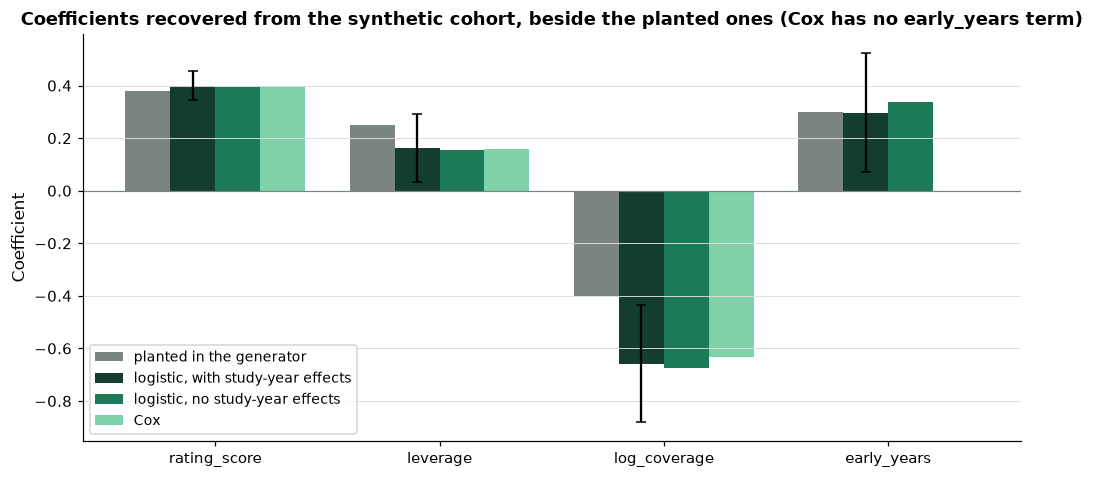

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(FEATURES))
width = 0.2
for offset, (column, colour) in enumerate([("planted in the generator", plotkit.GREY), ("logistic, with study-year effects", plotkit.GREEN_DARK),
                                           ("logistic, no study-year effects", plotkit.GREEN), ("Cox", plotkit.GREEN_LIGHT)]):
    values = coefficients[column]
    errors = 1.96 * coefficients["its standard error"] if column == "logistic, with study-year effects" else None
    ax.bar(x + (offset - 1.5) * width, values.fillna(0), width, yerr=errors, capsize=3, color=colour, label=column)
ax.axhline(0, color=plotkit.GREY, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(FEATURES)
ax.set_ylabel("Coefficient")
ax.set_title("Coefficients recovered from the synthetic cohort, beside the planted ones (Cox has no early_years term)")
ax.legend(loc="lower left", fontsize=9)
ax.grid(axis="x", visible=False)
plt.show()

* How to read it: four bars per covariate, the grey one planted, the dark one the fit with its 95 percent interval. Where the interval covers the grey bar, the fit is consistent with the truth. The Cox bar is missing for `early_years` because in a Cox model the age bump belongs to the baseline hazard.

Q. Add `hazard_to_survival` to `riskkit.py`, with its test.

In [26]:
%%writefile -a riskkit.py


def hazard_to_survival(hazards) -> np.ndarray:
    """A survival curve from a run of yearly hazards: the share still free of default after each year.

    Survival after year t is the product of (1 - hazard) over years 1 to t, the Kaplan-Meier product with a model's
    hazards in place of counted ones.
    Input: hazards, a 1-D array of yearly hazards, each from 0 to 1, in time order.
    Output: an array of the same length: survival after each year.
    Raises ValueError for an empty array, more than one dimension, a NaN, or a hazard outside [0, 1].
    """
    values = np.asarray(hazards, dtype=float)
    if values.ndim != 1 or len(values) == 0:
        raise ValueError("hazards must be a 1-D array of at least one value")
    if np.isnan(values).any() or ((values < 0) | (values > 1)).any():
        raise ValueError("every hazard must be from 0 to 1")
    return np.cumprod(1 - values)

Appending to riskkit.py


In [27]:
%%writefile -a test_riskkit.py


def test_hazard_to_survival_hand():
    assert riskkit.hazard_to_survival([0.1, 0.2, 0.0]).tolist() == pytest.approx([0.9, 0.72, 0.72])
    with pytest.raises(ValueError, match="from 0 to 1"):
        riskkit.hazard_to_survival([0.1, 1.5])

Appending to test_riskkit.py


In [28]:
importlib.reload(riskkit)
print(f"hazard_to_survival in riskkit: {hasattr(riskkit, 'hazard_to_survival')}")

hazard_to_survival in riskkit: True


In [29]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................                                                 [100%]
24 passed in 1.81s



* `24 passed`: day 4's 21 and today's 3. It is day 4's running product, fed with a model's hazards instead of counted ones.

Q. Take a typical firm of three ratings, hold its leverage and coverage where they started, and turn its fitted yearly hazards into a survival curve.

In [30]:
# a typical firm of three ratings: the median rating score, leverage, and coverage of the firms that entered there
entrants = firm_years[firm_years["years_since_entry"] == 1]
typical = entrants.groupby("rating_score")[["leverage", "coverage"]].median().loc[[9, 12, 15]]
typical.index = ["BBB (score 9)", "BB (score 12)", "B (score 15)"]

# its yearly hazards over 10 years, its covariates held where they started, then the survival curve they make
years = np.arange(1, 11)
curves = {}
for label, score in zip(typical.index, [9, 12, 15]):
    rows = pd.DataFrame({"const": 1.0, "rating_score": float(score), "leverage": typical.loc[label, "leverage"],
                         "log_coverage": np.log(typical.loc[label, "coverage"]), "early_years": ((years >= 2) & (years <= 4)).astype(float)})
    curves[label] = riskkit.hazard_to_survival(logit.predict(rows[["const"] + FEATURES]))
typical["survival past 5 years"] = [curves[label][4] for label in typical.index]
typical["survival past 10 years"] = [curves[label][9] for label in typical.index]
print(typical.round(4).to_string())

               leverage  coverage  survival past 5 years  survival past 10 years
BBB (score 9)     3.745     6.455                 0.9881                  0.9785
BB (score 12)     4.600     4.980                 0.9480                  0.9082
B (score 15)      5.550     3.750                 0.7861                  0.6470


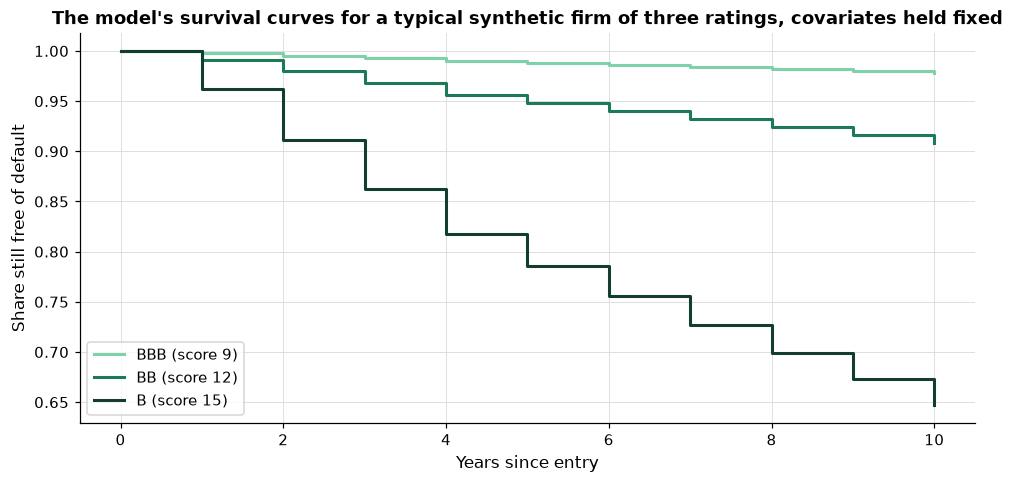

In [31]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
for (label, curve), colour in zip(curves.items(), [plotkit.GREEN_LIGHT, plotkit.GREEN, plotkit.GREEN_DARK]):
    ax.step(np.concatenate([[0], years]), np.concatenate([[1.0], curve]), where="post", color=colour, linewidth=2, label=label)
ax.set_xlabel("Years since entry")
ax.set_ylabel("Share still free of default")
ax.set_title("The model's survival curves for a typical synthetic firm of three ratings, covariates held fixed")
ax.legend(loc="lower left")
plt.show()

* Past 10 years the typical BBB firm is at 97.9% and the typical B firm at 64.7%. The B curve drops fastest in years 2 to 4, where the age bump sits.
* Holding a firm's covariates fixed is a simplification: a real firm's rating and leverage move, and its curve would bend with them. The curve is "the model's default probability for a firm that stayed as it entered", not a statement about any firm.

## Case Study: A Hazard Model Scored Walk-Forward

### Context

A colleague building a credit monitoring sheet asks: **if a firm-year hazard model had been fitted on the study years before each year, would it have ranked that year's defaults well, and would its default count have been the right size?**

The answer describes how a model would have scored on past study years of an invented cohort. It is not a forecast of defaults, it is not a credit decision, and it says nothing about any real firm.

### Objective

1. Fit the logistic hazard of section 5.4 (without study-year effects, which do not exist for a year not yet seen) on study years 1 to k - 1, and score year k, for k from 8 to 14.
2. Score the ranking by AUC, year by year.
3. Score the size: the model's default count against the counted one each year, and calibration by decile.
4. Say what the model shows, and where it fails.

### The data

`course5c_cohort.csv`: 4,000 **invented** firms, ids only, followed in study years, with covariates dated at the start of each year. The development years 1 to 14 only. **What the data leave open:** the generator's common factor of each study year is not in any column, so no model fitted on these columns can know whether a year will be a bad one.

## 5.5 Overview: the Years the Case Study Scores

In [32]:
# the study years the case study scores: each one's firm-years and defaults
overview = firm_years.groupby("study_year").agg(firm_years=("event", "size"), defaults=("event", "sum"))
overview["defaults per 100 firm-years"] = 100 * overview["defaults"] / overview["firm_years"]
overview.columns = ["firm-years", "defaults", "defaults per 100 firm-years"]
print(overview.loc[8:].round(2).to_string())

            firm-years  defaults  defaults per 100 firm-years
study_year                                                   
8                 1472        23                         1.56
9                 1620        32                         1.98
10                1724        45                         2.61
11                1792        20                         1.12
12                1897        23                         1.21
13                2008        40                         1.99
14                2101        45                         2.14


* Seven test years with between 20 and 45 defaults each. The default rate moves from year to year by more than the change in the firms' covariates would make it: day 3's clustering.

## 5.6 Model Building and Performance

Q. Walk forward by study year: fit on every year before the test year, score the test year, and record the AUC and the model's default count.

In [33]:
from sklearn.metrics import roc_auc_score

# walk forward by study year: fit on every year before the test year, score the test year, move on one year
scored, fold_rows = [], []
for test_year in range(8, DEVELOPMENT_END + 1):
    train = firm_years[firm_years["study_year"] < test_year]
    test = firm_years[firm_years["study_year"] == test_year].copy()
    # the past-only check, written out: study years are whole numbers, not dates, so mlkit.assert_past_only does not apply
    assert train["study_year"].max() < test_year, "a training year is not before the test year"
    fit = sm.Logit(train["event"], sm.add_constant(train[FEATURES])).fit(disp=0)
    test["fitted"] = fit.predict(sm.add_constant(test[FEATURES], has_constant="add"))
    scored.append(test)
    fold_rows.append({"test year": test_year, "training years": f"1 to {test_year - 1}", "firm-years": len(test),
                      "defaults": int(test["event"].sum()), "the model's defaults": test["fitted"].sum(),
                      "AUC": roc_auc_score(test["event"], test["fitted"])})
scored = pd.concat(scored)
walk_forward = pd.DataFrame(fold_rows).set_index("test year")
walk_forward["defaults over the model's"] = walk_forward["defaults"] / walk_forward["the model's defaults"]
print(walk_forward.round(3).to_string())
print(f"every training year before its test year: True; mean AUC {walk_forward['AUC'].mean():.3f}")

          training years  firm-years  defaults  the model's defaults    AUC  defaults over the model's
test year                                                                                             
8                 1 to 7        1472        23                25.754  0.842                      0.893
9                 1 to 8        1620        32                28.875  0.881                      1.108
10                1 to 9        1724        45                29.266  0.846                      1.538
11               1 to 10        1792        20                33.117  0.894                      0.604
12               1 to 11        1897        23                36.730  0.917                      0.626
13               1 to 12        2008        40                39.865  0.883                      1.003
14               1 to 13        2101        45                48.236  0.878                      0.933
every training year before its test year: True; mean AUC 0.877


In [34]:
plotkit.styled(walk_forward, ["AUC"], "Walk-forward by study year: AUC and the model's default count against the counted one",
               fmt="{:,.3f}")

,training years,firm-years,defaults,the model's defaults,AUC,defaults over the model's
test year,,,,,,
8,1 to 7,"1,472",23,25.754,0.842,0.893
9,1 to 8,"1,620",32,28.875,0.881,1.108
10,1 to 9,"1,724",45,29.266,0.846,1.538
11,1 to 10,"1,792",20,33.117,0.894,0.604
12,1 to 11,"1,897",23,36.730,0.917,0.626
13,1 to 12,"2,008",40,39.865,0.883,1.003
14,1 to 13,"2,101",45,48.236,0.878,0.933


* **Ranking holds.** The AUC runs from 0.842 to 0.917, a mean of 0.877, in every test year: the model puts the firm-years that defaulted well above most that did not.
* **Size does not.** Over the seven years the model's count is 242 against 228 counted, close in total. Year by year it misses: in year 10 there were 1.54 times the model's count, in year 11 only 0.60 times.

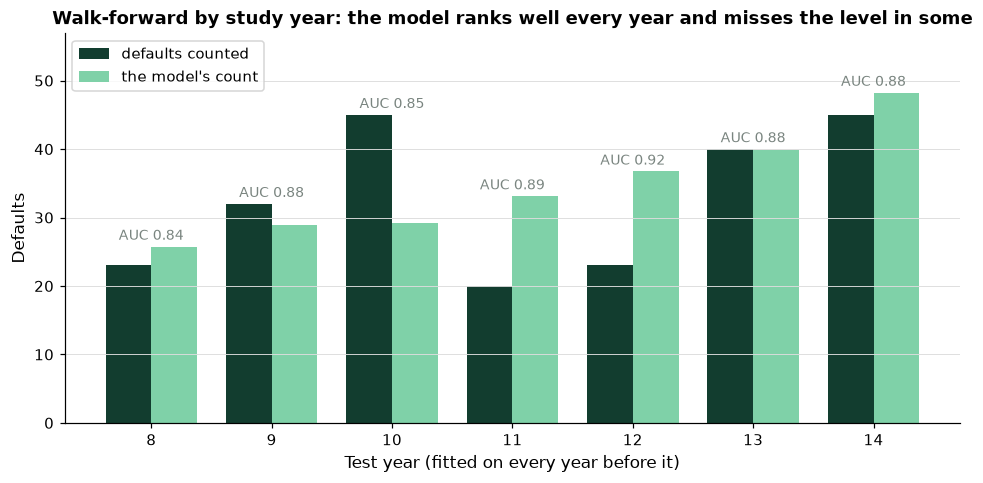

In [35]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
width = 0.38
ax.bar(walk_forward.index - width / 2, walk_forward["defaults"], width, color=plotkit.GREEN_DARK, label="defaults counted")
ax.bar(walk_forward.index + width / 2, walk_forward["the model's defaults"], width, color=plotkit.GREEN_LIGHT, label="the model's count")
for year, auc in walk_forward["AUC"].items():
    ax.annotate(f"AUC {auc:.2f}", xy=(year, max(walk_forward.loc[year, "defaults"], walk_forward.loc[year, "the model's defaults"]) + 1),
                ha="center", fontsize=9, color=plotkit.GREY)
ax.set_ylim(0, 1.18 * max(walk_forward["defaults"].max(), walk_forward["the model's defaults"].max()))
ax.set_xticks(walk_forward.index)
ax.set_xlabel("Test year (fitted on every year before it)")
ax.set_ylabel("Defaults")
ax.set_title("Walk-forward by study year: the model ranks well every year and misses the level in some")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

* How to read it: each year's pair of bars is the counted defaults and the sum of the model's fitted chances; the AUC sits on top. The AUC barely moves while the gap between the bars swings both ways: the model knows which firms are weaker, not which years are worse.

Q. Pool every scored firm-year and check calibration by decile of the fitted chance.

In [36]:
# calibration by decile: sort every scored firm-year by its fitted chance, cut into ten equal groups, and compare
scored["decile"] = pd.qcut(scored["fitted"], 10, labels=range(1, 11))
calibration = scored.groupby("decile", observed=True).agg(firm_years=("event", "size"), defaults=("event", "sum"),
                                                          mean_fitted=("fitted", "mean"), observed=("event", "mean"))
calibration["mean fitted (percent)"] = 100 * calibration["mean_fitted"]
calibration["observed (percent)"] = 100 * calibration["observed"]
calibration = calibration[["firm_years", "defaults", "mean fitted (percent)", "observed (percent)"]]
calibration.columns = ["firm-years", "defaults", "mean fitted (percent)", "observed (percent)"]
print(calibration.round(3).to_string())
print(f"share of all defaults in the top decile: {calibration['defaults'].iloc[-1] / calibration['defaults'].sum():.1%}")

        firm-years  defaults  mean fitted (percent)  observed (percent)
decile                                                                 
1             1262         0                  0.015               0.000
2             1261         1                  0.053               0.079
3             1261         1                  0.119               0.079
4             1262         2                  0.218               0.158
5             1261         6                  0.367               0.476
6             1261         5                  0.606               0.397
7             1262        15                  1.012               1.189
8             1261        24                  1.833               1.903
9             1261        51                  3.738               4.044
10            1262       123                 11.207               9.746
share of all defaults in the top decile: 53.9%


In [37]:
plotkit.styled(calibration, ["observed (percent)"], "Calibration by decile of the fitted chance, every walk-forward test "
               "firm-year pooled", fmt="{:,.3f}")

,firm-years,defaults,mean fitted (percent),observed (percent)
decile,,,,
1,"1,262",0,0.015,0.000
2,"1,261",1,0.053,0.079
3,"1,261",1,0.119,0.079
4,"1,262",2,0.218,0.158
5,"1,261",6,0.367,0.476
6,"1,261",5,0.606,0.397
7,"1,262",15,1.012,1.189
8,"1,261",24,1.833,1.903
9,"1,261",51,3.738,4.044


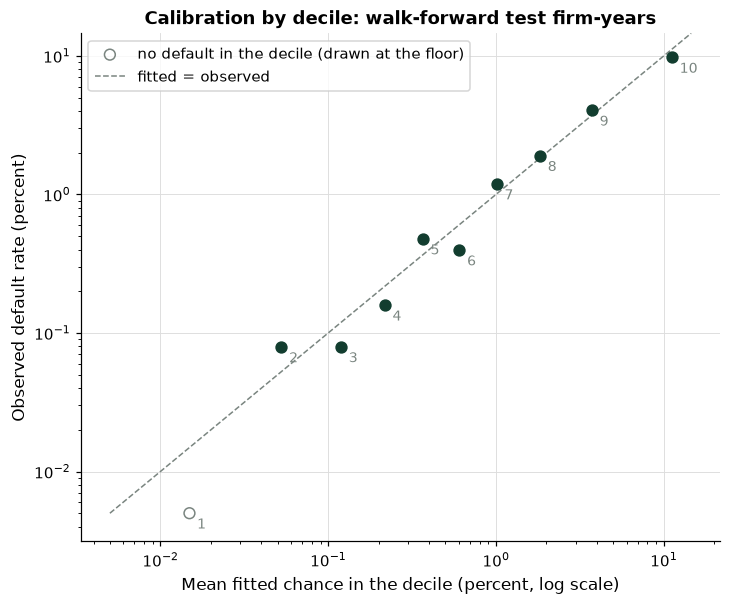

In [38]:
fig, ax = plt.subplots(figsize=(7.5, 6))
# a decile with no default cannot sit on a log scale: it is drawn hollow at a floor
FLOOR = 0.005
counted = calibration[calibration["defaults"] > 0]
none = calibration[calibration["defaults"] == 0]
ax.scatter(counted["mean fitted (percent)"], counted["observed (percent)"], color=plotkit.GREEN_DARK, s=50, zorder=3)
ax.scatter(none["mean fitted (percent)"], np.full(len(none), FLOOR), facecolors="none", edgecolors=plotkit.GREY, s=50,
           zorder=3, label="no default in the decile (drawn at the floor)")
for decile, row in calibration.iterrows():
    ax.annotate(str(decile), xy=(row["mean fitted (percent)"], max(row["observed (percent)"], FLOOR)), xytext=(5, -10),
                textcoords="offset points", fontsize=9, color=plotkit.GREY)
limit = 1.3 * max(calibration["mean fitted (percent)"].max(), calibration["observed (percent)"].max())
ax.plot([FLOOR, limit], [FLOOR, limit], color=plotkit.GREY, linestyle="--", linewidth=1, label="fitted = observed")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(FLOOR / 1.6, limit)
ax.set_xlabel("Mean fitted chance in the decile (percent, log scale)")
ax.set_ylabel("Observed default rate (percent)")
ax.set_title("Calibration by decile: walk-forward test firm-years")
ax.legend(loc="upper left")
plt.show()

* How to read it: each point is a tenth of the scored firm-years, numbered from the lowest fitted chances to the highest; on the dashed line the fitted chance and the observed rate agree. The points follow the line across two orders of magnitude.
* The top decile holds 54% of all the defaults, at an observed rate of 9.75 percent against a fitted 11.21 percent. The bottom five deciles hold 10 defaults between them: that end of the scale is the low-default problem again, and its points rest on almost nothing.

## 5.7 What the Model Shows, and Where It Fails

**What the model shows.** On the synthetic cohort's development years, a logistic hazard on rating score, leverage, log coverage, and the early-years bump, fitted on the study years before each test year, ranked the test years' firm-years with an AUC between 0.842 and 0.917, and its fitted chances follow the observed rates decile by decile. Its coefficients come close to the ones the generator planted, and the Cox model, which leaves the baseline free, gives nearly the same answers. Firm-level covariates sort the firms well.

**Where it fails.**

* **On the level of a year.** The model's default count misses by a factor of 1.54 in year 10 and 0.60 in year 11. The generator's common factor of each year is in no column, so a model on these columns averages over good and bad years and is right only on average. Day 3's correlated defaults are exactly that factor.
* **On one coefficient.** Log coverage is -2.28 standard errors from its planted value on these years: a real gap for a sample of 345 defaults, which a single fit gives no way to see.
* **On sector.** With nine sector indicators, 3 came out with small p-values although the generator has no sector term: a reminder that a covariate's apparent effect can be chance in the base group.
* **On the low end.** The bottom half of the deciles holds 10 defaults, so the model's small default chances for strong firms rest on the logistic line, not on counted defaults.

**What the data cannot support.** A walk-forward score on past study years describes how a model would have done on them. It is not evidence about a later year, it is not a credit decision about any firm, and the firms are invented.

**What was not tested.** Other covariates or their interactions, a model with the year factor estimated as it goes, rating changes as events of their own, and the held-out years 15 to 20, which stay closed until the capstone.

## A Story: The Model Nobody Noticed for a While

In 1993 Nancy Reid recorded a conversation with David Cox, published in *Statistical Science* the next year. Asked about the background to his 1972 paper, Cox said that several people "said they were getting a certain kind of data, censored survival data, with a lot of explanatory variables. Nobody knew quite how to handle this sort of data in a reasonably general way". Approaching it through the hazard, he said, was "entirely natural". He remembered the paper as "written extremely quickly", and that "Nobody took much notice of the 1972 paper for a while, until various people started to write software which was widely useful": "6 or 7 years". Asked about its most positive benefits, he named first "Handling in-study covariates, that is, time-dependent covariates".

The point for a desk: today's model rests on that last answer. A firm's rating, leverage, and coverage change every year, and the model uses each year's values. It took software to make the method common, which is why a desk can now fit it in one line.

Sources: N. Reid, "A Conversation with Sir David Cox", *Statistical Science* 9 (3), 1994, pages 439 to 455 (the quotes are on pages 449 and 450); D. R. Cox, "Regression Models and Life-Tables", *Journal of the Royal Statistical Society, Series B* 34 (2), 1972, pages 187 to 220. The discrete-time hazard of section 5.4: T. Shumway, *Journal of Business* 74 (1), 2001, pages 101 to 124.

## Excel Side by Side

Excel cannot fit a Cox model or a logistic regression without Solver, but every number a fitted model hands over can be checked in a cell. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-24). The check pasted the last fold's five coefficients into B1:B5 and one of its year-14 test rows into C1:C5 (a 1 first, for the constant), the Cox model's rating coefficient and its standard error into E1:E2, the typical BB firm's ten yearly hazards into G1:G10, and the 12,614 scored firm-years' deciles and events into J2:K12615.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| A firm-year's fitted hazard | `fit.predict(...)` | `=1/(1+EXP(-SUMPRODUCT(B1:B5,C1:C5)))` | 0.005706 |
| The rating score's hazard ratio | `np.exp(cox.params)` | `=EXP(E1)` | 1.488706 |
| Its 95 percent interval | `np.exp(cox.conf_int())` | `=EXP(E1-NORM.S.INV(0.975)*E2)` and `=EXP(E1+NORM.S.INV(0.975)*E2)` | 1.4111 to 1.5706 |
| Survival past 10 years from 10 hazards | `riskkit.hazard_to_survival(h)[-1]` | `=PRODUCT(1-G1:G10)` | 0.908156 |
| The top decile's observed default rate | `scored.groupby("decile")["event"].mean()` | `=AVERAGEIFS(K2:K12615,J2:J12615,10)` | 0.097464 |

**A fitted hazard.** `SUMPRODUCT(B1:B5,C1:C5)` is the linear term, a + b1 x1 + ..., and `1/(1+EXP(-...))` turns it into a chance: the logistic function, as on day 3. **A hazard ratio** is `EXP` of a coefficient, and its interval is `EXP` of the coefficient plus and minus `NORM.S.INV(0.975)` standard errors: 1.959964, which statsmodels uses exactly; typing 1.96 moves the interval in its sixth decimal.

**A survival curve.** `PRODUCT(1-G1:G10)` multiplies the ten shares that got through each year in one cell (an array formula; Excel 365 evaluates it as one). The running product of day 4 does the same row by row.

**Calibration.** `AVERAGEIFS` of the events where the decile is 10 is the top decile's observed rate. Excel has no AUC function; the case study's AUC is scikit-learn's.

In [39]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [0.00570635755900487, 1.4887060083669437, 1.4110963461500043, 1.5705841669809302, 0.9081555108990486, 0.09746434231378764],
    "Python": [0.0057063575590048645, hazard_ratios.loc["rating_score", "hazard ratio"], hazard_ratios.loc["rating_score", "95% low"],
               hazard_ratios.loc["rating_score", "95% high"], curves["BB (score 12)"][-1], calibration["observed (percent)"].iloc[-1] / 100],
}, index=pd.Index(["a year-14 firm-year's fitted hazard", "rating score hazard ratio", "its 95% low", "its 95% high",
                    "typical BB firm: survival past 10 years", "top decile: observed default rate"], name="Check"))
excel_side["equal within 1e-9"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-9
plotkit.styled(excel_side, [], "Excel beside Python on a fitted hazard, a hazard ratio, a survival curve, and calibration",
               fmt="{:,.6f}")

,Excel,Python,equal within 1e-9
Check,,,
a year-14 firm-year's fitted hazard,0.005706,0.005706,True
rating score hazard ratio,1.488706,1.488706,True
its 95% low,1.411096,1.411096,True
its 95% high,1.570584,1.570584,True
typical BB firm: survival past 10 years,0.908156,0.908156,True
top decile: observed default rate,0.097464,0.097464,True


* Every value is equal within 1e-9.

## Save the Day with Git

Today's Git step names a version of the module. The end of week 1 is a natural point to mark: a **tag** is a name for one commit that stays put however many commits follow, so `week1` will always mean the module as it stood today.

Q. Start a repository in the work folder, commit the code, and tag the commit.

In [40]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [41]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5c_05__wakm9_o and nowhere else


In [42]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [43]:
# -a makes an annotated tag with a message; tag -n lists tags and their messages
!git -C "{work}" add .gitignore mlkit.py riskkit.py test_riskkit.py
!git -C "{work}" commit -q -m "Day 5: riskkit with person_period and hazard_to_survival"
!git -C "{work}" tag -a week1 -m "Course 5C week 1: simulation and default"
!git -C "{work}" tag -n
!git -C "{work}" log --oneline --decorate

week1           Course 5C week 1: simulation and default


492487d (HEAD -> main, tag: week1) Day 5: riskkit with person_period and hazard_to_survival


## Bring It Home

Add today's functions to your own `my_bondmath` folder, and tag the end of week 1. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `riskkit.py` and paste the code of today's two `riskkit.py` cells (sections 5.1 and 5.4) at the end, without their first lines. Do the same for the two `test_riskkit.py` cells in `test_riskkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_riskkit.py
```

The last line says `24 passed`.

**Step 4.** Commit, and tag the end of the week.

```powershell
git add riskkit.py test_riskkit.py
git commit -m "Day 5: riskkit with person_period and hazard_to_survival"
git tag -a week1-riskkit -m "riskkit at the end of Course 5C week 1"
```

## You Can Now

* Build a person-period table of firm-years and check its history (`person_period`).
* Fit a Cox model with covariates that change year by year, read hazard ratios and their intervals, and sweep its settings.
* Check the proportional-hazards assumption by fitting early and later years apart.
* Fit a discrete-time hazard on firm-years, and set its coefficients beside a known truth.
* Turn yearly hazards into a survival curve (`hazard_to_survival`).
* Score a hazard model walk-forward by AUC and calibration, and say what it shows and where it fails: it ranked with an AUC of 0.877 on average and missed the level of the bad years.

Week 1 is done: simulation, VaR, correlated defaults, survival, and hazard. Next, week 2, day 1: outliers and robust rules, starting with off-market prints in the trade blotter.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It builds the firm-year table, fits the Cox model of section 5.2 and the logistic hazard of section 5.4, and defines `check`, a small function that marks your answers.

In [44]:
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from statsmodels.duration.hazard_regression import PHReg

# the synthetic cohort's development years: invented firms, study years 1 to 14
cohort = pd.read_csv("course5c_cohort.csv")
DEVELOPMENT_END = 14
firm_years = riskkit.person_period(cohort[cohort["study_year"] <= DEVELOPMENT_END])
print(f"{len(firm_years):,} firm-years of {firm_years['firm_id'].nunique():,} firms; {int(firm_years['event'].sum())} defaults")
print(firm_years[firm_years["firm_id"] == firm_years.loc[firm_years["event"] == 1, "firm_id"].iloc[0]].to_string(index=False))

# the Cox model of section 5.2 and the logistic hazard of section 5.4
COVARIATES = ["rating_score", "leverage", "log_coverage"]
cox = PHReg(firm_years["years_since_entry"], firm_years[COVARIATES], status=firm_years["event"],
            entry=firm_years["years_since_entry"] - 1, ties="efron").fit()
FEATURES = ["rating_score", "leverage", "log_coverage", "early_years"]
logit = sm.Logit(firm_years["event"], sm.add_constant(firm_years[FEATURES])).fit(disp=0)


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

18,503 firm-years of 3,504 firms; 345 defaults
firm_id  study_year  years_since_entry   sector rating  rating_score  leverage  coverage  default  exit  event  log_coverage  early_years
  F0002           1                  1 Consumer      B            15      4.92      7.18        0     0      0      1.971299            0
  F0002           2                  2 Consumer      B            15      5.09      9.72        1     0      1      2.274186            1


### Exercise 1

Q. By how much does the Cox model multiply a firm's hazard when its rating falls two notches, other things equal? Store the factor in **ex1_two_notches**.

In [45]:
ex1_two_notches = ...

In [46]:
check("Exercise 1 hazard ratio for two notches", ex1_two_notches, 2.216245579347839)

Exercise 1 hazard ratio for two notches: not attempted yet


### Exercise 2

Q. An invented firm enters with a rating score of 13, leverage of 4.5 times, and interest coverage of 3.0 times, and keeps them. With the logistic hazard of section 5.4 and `riskkit.hazard_to_survival`, what is its chance of default within 5 years? Remember `early_years` is 1 in years 2 to 4. Store it in **ex2_default_5**.

In [47]:
ex2_default_5 = ...

In [48]:
check("Exercise 2 default within 5 years", ex2_default_5, 0.10343338179337491)

Exercise 2 default within 5 years: not attempted yet


### Exercise 3

Q. Add a function to your module. `calibration_by_decile(fitted, event, n_groups=10)` sorts the rows by fitted chance, cuts them into `n_groups` equal groups with `pd.qcut`, and returns each group's rows, events, mean fitted chance, and observed share. It refuses mismatched lengths, a chance outside [0, 1], an event other than 0 or 1, and fewer than 2 groups. Write the docstring first. Add `test_calibration_by_decile_hand`, which checks fitted chances 0.9, 0.1, 0.7, 0.2 with events 1, 0, 0, 0 in 2 groups. Run pytest, reload the module, and store the observed default rate of the top decile of the in-sample logistic hazard's fitted chances on all the firm-years in **ex3_top_observed**.

Write the function in the cell that starts with `%%writefile -a riskkit.py` and the test in the one that starts with `%%writefile -a test_riskkit.py`, and run each of those cells once.

In [49]:
%%writefile -a riskkit.py


# Exercise 3: write calibration_by_decile(fitted, event, n_groups) below this line

Appending to riskkit.py


In [50]:
%%writefile -a test_riskkit.py


# Exercise 3: write test_calibration_by_decile_hand() below this line

Appending to test_riskkit.py


In [51]:
# run pytest, reload the module, then use your function
ex3_top_observed = ...

In [52]:
check("Exercise 3 top decile observed rate, in sample", ex3_top_observed, 0.10588870880605078)

Exercise 3 top decile observed rate, in sample: not attempted yet


### Exercise 4

Q. Rerun the walk-forward of section 5.6 with the rating score as the only covariate. What is the mean AUC over the seven test years? Store it in **ex4_mean_auc**, and compare it with the full model's.

In [53]:
ex4_mean_auc = ...

In [54]:
check("Exercise 4 mean AUC, rating score only", ex4_mean_auc, 0.8608041030084376)

Exercise 4 mean AUC, rating score only: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that adds the model's inputs to firm-year rows, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The model's inputs for each firm-year, every one known at the start of that year.

    rows: firm-year rows with firm_id, study_year, years_since_entry, and coverage.
    Adds log_coverage (the natural log of coverage), early_years (1 in years 2 to 4 since entry), and
    years_watched (how many years the firm has been watched so far, this one included).
    Returns a copy with the three columns added.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, adds the three columns, and contains one bug.

In [55]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def add_features(rows):
    """The model's inputs for each firm-year, every one known at the start of that year.

    rows: firm-year rows with firm_id, study_year, years_since_entry, and coverage.
    Adds log_coverage (the natural log of coverage), early_years (1 in years 2 to 4 since entry), and
    years_watched (how many years the firm has been watched so far, this one included).
    Returns a copy with the three columns added.
    """
    out = rows.copy()
    out["log_coverage"] = np.log(out["coverage"])
    out["early_years"] = out["years_since_entry"].between(2, 4).astype(int)
    # how long the firm has been watched
    out["years_watched"] = out.groupby("firm_id")["years_since_entry"].transform("max")
    return out

Q. Before you run the next cell: should a firm-year's `years_watched` depend on rows from later years? Look at the first rows of a firm that defaulted.

In [56]:
features = add_features(firm_years)
example = features["firm_id"][features["event"] == 1].iloc[0]
print(features.loc[features["firm_id"] == example, ["firm_id", "study_year", "years_since_entry", "event", "years_watched"]].to_string(index=False))

firm_id  study_year  years_since_entry  event  years_watched
  F0002           1                  1      0              2
  F0002           2                  2      1              2


Q. Test the function against its docstring before you trust it: an input known at the start of year 10 cannot change when the later years are added to the rows.

In [57]:
# the test, written from the docstring before the code is trusted
# an input known at the start of year 10 cannot change when the later years are added to the rows
through_10 = add_features(firm_years[firm_years["study_year"] <= 10])
all_years = add_features(firm_years)
year_10_short = through_10[through_10["study_year"] == 10].set_index("firm_id")["years_watched"]
year_10_full = all_years[all_years["study_year"] == 10].set_index("firm_id")["years_watched"]
changed = int((year_10_short != year_10_full.loc[year_10_short.index]).sum())
assert changed == 0, f"{changed} firms' year-10 inputs change when later years are added: the inputs look ahead"
print(f"year-10 inputs unchanged by the later years for all {len(year_10_short):,} firms")

AssertionError: 1552 firms' year-10 inputs change when later years are added: the inputs look ahead

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the mean of the fixed `years_watched` over all the firm-years, `float(add_features(firm_years)["years_watched"].mean())`, in **ex5_mean**.

In [58]:
# fix the function above and run the test again, then store the answer
ex5_mean = ...

In [59]:
check("Exercise 5 mean years watched, fixed function", ex5_mean, 4.393719937307464)

Exercise 5 mean years watched, fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```